# 🌾 RICE VISION AI — HỆ THỐNG BENCHMARK & ĐÁNH GIÁ KIỂM NGHIỆM 100 MẪU THỰC ĐỊA

Sổ tay này được thiết kế để tự động hóa quy trình **kiểm nghiệm và đánh giá độ chính xác** của toàn bộ hệ thống Rice Vision AI trên tập dữ liệu thực địa gồm **100 mẫu ngẫu nhiên** (được lưu trữ tại `AI_SERVICES/test_data/`).

### 🎯 Mục tiêu kiểm định (Phiên bản tích hợp SOTA Bayesian Few-Shot Calibration - FromThanh):
1. **Đo lường độ chính xác tổng thể**: Đánh giá chỉ số $R^2$, MAE (sai số hạt trung bình), RMSE, MAPE (%) so với số đếm thủ công (Ground Truth).
2. **Đánh giá Khoảng tin cậy 90% (CI90)**: Kiểm tra tỷ lệ bao phủ thực nghiệm (Coverage Probability) của mô hình Bayesian Hybrid.
3. **So sánh đa phương pháp đối đầu (Benchmarking)**: Đối chiếu trực tiếp giữa **Bayesian Hybrid (FromThanh)**, **Hồi quy Extra Trees**, **Thuần hình học 3D (Geometry)** và **Cân điện tử (Weight)**.
4. **Kiểm tra độ ổn định & thời gian đáp ứng**: Thống kê độ trễ suy luận trung bình (latency) qua các giai đoạn (SAHI, YOLO, Watershed, CNN, Feature Assembly, Bayes/Regression).
5. **Xuất báo cáo chi tiết**: Xuất bảng kết quả kiểm định ra Excel/CSV/JSON phục vụ báo cáo khoa học và nghiệm thu.

In [1]:
# =============================================================================
# 1. KHỞI TẠO MÔI TRƯỜNG & HỖ TRỢ TƯƠNG THÍCH HYBRID (LOCAL / GOOGLE COLAB)
# =============================================================================
import os
import sys
import time
import json
import subprocess
from pathlib import Path

# 1.1 Tự động phát hiện môi trường Google Colab
IS_COLAB = 'google.colab' in sys.modules
if IS_COLAB:
    print("⚡ Phát hiện môi trường Google Colab!")
    # Mount Google Drive nếu chưa mount
    if not Path('/content/drive').exists():
        from google.colab import drive
        drive.mount('/content/drive')

    # Cài đặt thư viện phụ thuộc nếu thiếu trên Colab
    try:
        import sahi
        import ultralytics
        import openpyxl
    except ImportError:
        print("📦 Đang cài đặt thư viện bổ trợ (sahi, ultralytics, openpyxl) trên Colab...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "sahi", "ultralytics", "openpyxl"])

    # Tự động định vị thư mục AI_SERVICES trên Google Drive hoặc cục bộ
    candidates = [
        Path('/content/drive/MyDrive/NGHIÊN CỨU KHOA HỌC/GROUP_MEMBERS/NGUYEN MINH TRI/MAIN_SOURCES/AI_SERVICES'),
        Path('/content/drive/MyDrive/MAIN_SOURCES/AI_SERVICES'),
        Path('/content/drive/MyDrive/AI_SERVICES'),
        Path('/content/AI_SERVICES'),
        Path.cwd() if Path.cwd().name == 'AI_SERVICES' else Path.cwd() / 'AI_SERVICES',
        Path.cwd()
    ]
    AI_SERVICES_DIR = None
    for c in candidates:
        if (c / 'src' / 'rice_ai').is_dir():
            AI_SERVICES_DIR = c
            break
    if AI_SERVICES_DIR is None:
        # Tìm kiếm trên Drive
        drive_matches = list(Path('/content/drive/MyDrive').glob('**/AI_SERVICES'))
        for dm in drive_matches:
            if (dm / 'src' / 'rice_ai').is_dir():
                AI_SERVICES_DIR = dm
                break
    if AI_SERVICES_DIR is None:
        AI_SERVICES_DIR = Path('/content/drive/MyDrive/NGHIÊN CỨU KHOA HỌC/GROUP_MEMBERS/NGUYEN MINH TRI/MAIN_SOURCES/AI_SERVICES')
else:
    print("💻 Phát hiện môi trường Local Machine.")
    CURRENT_DIR = Path.cwd()
    if 'AI_SERVICES' in str(CURRENT_DIR):
        AI_SERVICES_DIR = CURRENT_DIR if CURRENT_DIR.name == 'AI_SERVICES' else [p for p in CURRENT_DIR.parents if p.name == 'AI_SERVICES'][0]
    else:
        AI_SERVICES_DIR = CURRENT_DIR / 'AI_SERVICES'

SRC_DIR = AI_SERVICES_DIR / 'src'
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))
if str(AI_SERVICES_DIR) not in sys.path:
    sys.path.insert(0, str(AI_SERVICES_DIR))

# 1.2 Kiểm tra phần cứng và tăng tốc GPU (CUDA)
import torch
cuda_available = torch.cuda.is_available()
if cuda_available:
    gpu_name = torch.cuda.get_device_name(0)
    print(f"🚀 TĂNG TỐC GPU KÍCH HOẠT: {gpu_name} (Tốc độ suy luận sẽ cực kỳ nhanh!)")
else:
    print("ℹ️ Đang chạy trên CPU. (Nếu chạy trên Colab, hãy bật GPU tại: Runtime -> Change runtime type -> T4 GPU)")

print(f"✅ Đã liên kết thư mục mã nguồn lõi: {SRC_DIR}")
print(f"📁 Thư mục gốc AI_SERVICES: {AI_SERVICES_DIR}")


⚡ Phát hiện môi trường Google Colab!
Mounted at /content/drive
📦 Đang cài đặt thư viện bổ trợ (sahi, ultralytics, openpyxl) trên Colab...
🚀 TĂNG TỐC GPU KÍCH HOẠT: Tesla T4 (Tốc độ suy luận sẽ cực kỳ nhanh!)
✅ Đã liên kết thư mục mã nguồn lõi: /content/drive/MyDrive/NGHIÊN CỨU KHOA HỌC/GROUP_MEMBERS/NGUYEN MINH TRI/MAIN_SOURCES/AI_SERVICES/src
📁 Thư mục gốc AI_SERVICES: /content/drive/MyDrive/NGHIÊN CỨU KHOA HỌC/GROUP_MEMBERS/NGUYEN MINH TRI/MAIN_SOURCES/AI_SERVICES


In [2]:
# =============================================================================
# 2. NẠP CẤU HÌNH & XÁC THỰC KHO MÔ HÌNH ARTIFACTS
# =============================================================================
from pathlib import Path
from rice_ai.settings import Settings
from rice_ai.api.application import create_app
from fastapi.testclient import TestClient

settings = Settings()

print("🔍 KIỂM TRA ĐƯỜNG DẪN MÔ HÌNH TRIỂN KHAI:")
yolo_path = settings.get_yolo_path()
cnn_path = settings.get_cnn_path()
reg_dir = settings.get_regression_dir()

try:
    bayes_path = settings.get_bayes_params_path()
    bayes_name = bayes_path.name
except Exception as ex:
    bayes_path = None
    bayes_name = f'Chưa cấu hình ({ex})'

print(f"   • YOLOv8m Weights    : {yolo_path.name} ({yolo_path.stat().st_size / 1e6:.2f} MB)")
print(f"   • CNN DenseNet121    : {cnn_path.name} ({cnn_path.stat().st_size / 1e6:.2f} MB)")
print(f"   • Regression Bundle  : {reg_dir.name}")
if bayes_path and Path(bayes_path).exists():
    print(f"   • Bayesian Calibrator: {bayes_name} ✨ (FromThanh SOTA)")
else:
    print(f"   • Bayesian Calibrator: {bayes_name}")
print(f"   • Thiết bị YOLO      : {settings.get_yolo_device()}")
print(f"   • Hệ số hình học     : {settings.packing_fraction_geometry}")

# Khởi tạo ứng dụng FastAPI và Client nội bộ
app = create_app(settings=settings)

# Kiểm tra trạng thái hệ thống trong lifespan
with TestClient(app) as client:
    status_res = client.get("/api/status")
    status_data = status_res.json()
    print(f"\n🚀 Trạng thái hệ thống: {status_data.get('readiness', 'unknown').upper()}")
    components = status_data.get('components', {})
    if 'bayes' in components:
        print(f"   ✨ Mô-đun Bayes: {components['bayes'].get('status', '').upper()} ({components['bayes'].get('path', '')})")


🔍 KIỂM TRA ĐƯỜNG DẪN MÔ HÌNH TRIỂN KHAI:
   • YOLOv8m Weights    : best.pt (54.84 MB)
   • CNN DenseNet121    : best_v3_step2.keras (41.35 MB)
   • Regression Bundle  : extra_trees
   • Bayesian Calibrator: bayes_params_v1.json ✨ (FromThanh SOTA)
   • Thiết bị YOLO      : cuda:0
   • Hệ số hình học     : 0.55

🚀 Trạng thái hệ thống: READY
   ✨ Mô-đun Bayes: LOADED ()


In [3]:
# =============================================================================
# 3. NẠP DỮ LIỆU KIỂM THỬ (100 MẪU GROUND TRUTH)
# =============================================================================
import pandas as pd

TEST_DATA_DIR = AI_SERVICES_DIR / 'test_data'
RAW_IMG_DIR = TEST_DATA_DIR / '1_Raw_Images'
EXCEL_PATH = TEST_DATA_DIR / '2_Manual_Records' / 'manual_data.xlsx'

if not EXCEL_PATH.exists():
    raise FileNotFoundError(f"Không tìm thấy tệp {EXCEL_PATH}. Vui lòng kiểm tra lại test_data.")

df_ground_truth = pd.read_excel(EXCEL_PATH)
print(f"📊 Tổng số mẫu trong tập kiểm thử: {len(df_ground_truth)} mẫu")

# Kiểm tra sự tồn tại của tệp ảnh cho từng mẫu
df_ground_truth['image_exists'] = df_ground_truth['Sample_ID'].apply(
    lambda sid: (RAW_IMG_DIR / f"{str(sid).strip()}.jpg").exists()
)
valid_count = df_ground_truth['image_exists'].sum()
print(f"📸 Số mẫu có tệp ảnh hợp lệ trên đĩa: {valid_count} / {len(df_ground_truth)}")

# Thống kê sơ bộ về tập Ground Truth
gt_stats = df_ground_truth['Actual_Count'].describe()
print("\n📈 Phân phối số hạt thực tế (Actual_Count):")
print(f"   • Tối thiểu (Min)    : {gt_stats['min']:.0f} hạt")
print(f"   • Trung bình (Mean)  : {gt_stats['mean']:.1f} hạt")
print(f"   • Trung vị (Median)  : {gt_stats['50%']:.1f} hạt")
print(f"   • Tối đa (Max)       : {gt_stats['max']:.0f} hạt")

df_ground_truth[['Sample_ID', 'Weight_g', 'Inner_Diameter_mm', 'Container_Height_mm', 'Empty_Height_mm', 'Actual_Count']].head(10)

📊 Tổng số mẫu trong tập kiểm thử: 74 mẫu
📸 Số mẫu có tệp ảnh hợp lệ trên đĩa: 74 / 74

📈 Phân phối số hạt thực tế (Actual_Count):
   • Tối thiểu (Min)    : 20 hạt
   • Trung bình (Mean)  : 218.8 hạt
   • Trung vị (Median)  : 200.0 hạt
   • Tối đa (Max)       : 470 hạt


,Sample_ID,Weight_g,Inner_Diameter_mm,Container_Height_mm,Empty_Height_mm,Actual_Count
0,M0001,0.53,17.8,33.5,29.8,20
1,M0002,0.53,17.8,33.5,29.8,20
2,M0003,0.80,17.8,33.5,26.3,30
3,M0004,0.80,17.8,33.5,26.3,30
4,M0005,1.06,17.8,33.5,25.1,40
5,M0006,1.06,17.8,33.5,25.1,40
6,M0007,1.34,17.8,33.5,23.2,50
7,M0008,1.34,17.8,33.5,23.2,50
8,M0009,1.60,17.8,33.5,20.2,60
9,M0010,1.60,17.8,33.5,20.2,60


In [4]:
# =============================================================================
# 4. THỰC THI SUY LUẬN HÀNG LOẠT (BATCH INFERENCE RUNNER — BAYESIAN HYBRID)
# =============================================================================
import time
from tqdm.auto import tqdm

# Cấu hình số lượng mẫu muốn chạy kiểm thử:
# Đặt NUM_SAMPLES_TO_RUN = None để chạy toàn bộ 100 mẫu.
# Đặt ví dụ = 10 nếu bạn muốn chạy thử nghiệm nhanh trước.
NUM_SAMPLES_TO_RUN = None  # None = chạy toàn bộ 100 mẫu

samples_df = df_ground_truth[df_ground_truth['image_exists']].copy()
if NUM_SAMPLES_TO_RUN is not None:
    samples_df = samples_df.iloc[:NUM_SAMPLES_TO_RUN].copy()

total_samples = len(samples_df)
print(f"🏁 Bắt đầu chạy suy luận trên {total_samples} mẫu với chế độ Bayesian Hybrid SOTA...")
results_records = []

with TestClient(app) as test_client:
    total_pbar = tqdm(total=total_samples, desc="🚀 Tổng tiến độ kiểm nghiệm", position=0)

    for idx, (_, row) in enumerate(samples_df.iterrows(), start=1):
        sample_id = str(row['Sample_ID']).strip()
        img_file = RAW_IMG_DIR / f"{sample_id}.jpg"
        actual_count = float(row['Actual_Count'])

        data_payload = {
            "diam": float(row['Inner_Diameter_mm']),
            "height": float(row['Container_Height_mm']),
            "empty": float(row['Empty_Height_mm']),
            "weight_total": float(row['Weight_g']),
            "estimator_mode": "auto",  # Tự động ưu tiên Bayesian Hybrid (FromThanh) + đối chiếu ExtraTrees
            "debug": "true"
        }

        sample_desc = f"[{idx:03d}/{total_samples:03d}] Mẫu {sample_id:<6}"
        with tqdm(total=1, desc=sample_desc, leave=True) as sample_pbar:
            t_start = time.perf_counter()
            with open(img_file, "rb") as f:
                res = test_client.post(
                    "/predict",
                    data=data_payload,
                    files={"file": (img_file.name, f, "image/jpeg")}
                )
            latency_ms = (time.perf_counter() - t_start) * 1000

            if res.status_code == 200:
                payload = res.json()
                est = payload.get("estimation", {})
                final_est = est.get("final")
                reg_est = est.get("regression_est")
                geo_est = est.get("geometry_est")
                weight_est = est.get("weight_est")
                method = est.get("method_used", "unknown")

                # Trích xuất dữ liệu chuyên sâu từ mô-đun Bayes (FromThanh)
                bayes_info = est.get("bayes_est") or {}
                bayes_est = bayes_info.get("predicted_count") or bayes_info.get("estimate")
                ci90_lower = bayes_info.get("ci90_lower")
                ci90_upper = bayes_info.get("ci90_upper")
                ci90_width_pct = bayes_info.get("relative_ci90_width_pct")

                # Phân rã 2 nhánh con: Thị giác thuần vs Có cân hỗ trợ
                branches = bayes_info.get("branch_estimates", {})
                vision_only_est = branches.get("vision_only", {}).get("predicted_count")
                weight_assisted_est = branches.get("weight_assisted", {}).get("predicted_count")

                # Cờ phát hiện bất thường cân nặng 3-sigma
                disagreement_flag = bayes_info.get("disagreement_flag", False)

                abs_error = abs(final_est - actual_count) if final_est is not None else None
                pct_error = (abs_error / actual_count * 100.0) if (abs_error is not None and actual_count > 0) else None

                # Kiểm tra Ground Truth có nằm trong Khoảng tin cậy 90% không
                in_ci90 = None
                if ci90_lower is not None and ci90_upper is not None:
                    in_ci90 = bool(ci90_lower <= actual_count <= ci90_upper)

                results_records.append({
                    "Sample_ID": sample_id,
                    "Actual_Count": actual_count,
                    "Final_Estimate": final_est,
                    "Bayes_Estimate": bayes_est,
                    "CI90_Lower": ci90_lower,
                    "CI90_Upper": ci90_upper,
                    "In_CI90": in_ci90,
                    "CI90_Width_Pct": ci90_width_pct,
                    "Vision_Only_Est": vision_only_est,
                    "Weight_Assisted_Est": weight_assisted_est,
                    "Regression_Estimate": reg_est,
                    "Geometry_Estimate": geo_est,
                    "Weight_Estimate": weight_est,
                    "Disagreement_Flag": disagreement_flag,
                    "Method_Used": method,
                    "Abs_Error": abs_error,
                    "Pct_Error": pct_error,
                    "Latency_ms": latency_ms,
                    "Status": "SUCCESS"
                })

                ci_str = f"[{ci90_lower:.0f}-{ci90_upper:.0f}]" if (ci90_lower is not None and ci90_upper is not None) else "N/A"
                status_str = f"Thật: {actual_count:.0f} | Bayes: {final_est:.1f} (CI90: {ci_str}, Lệch: {abs_error:.1f} hạt, {latency_ms:.0f}ms)"
                sample_pbar.set_postfix_str(status_str)
            else:
                results_records.append({
                    "Sample_ID": sample_id,
                    "Actual_Count": actual_count,
                    "Final_Estimate": None,
                    "Bayes_Estimate": None,
                    "CI90_Lower": None,
                    "CI90_Upper": None,
                    "In_CI90": None,
                    "CI90_Width_Pct": None,
                    "Vision_Only_Est": None,
                    "Weight_Assisted_Est": None,
                    "Regression_Estimate": None,
                    "Geometry_Estimate": None,
                    "Weight_Estimate": None,
                    "Disagreement_Flag": None,
                    "Method_Used": "ERROR",
                    "Abs_Error": None,
                    "Pct_Error": None,
                    "Latency_ms": latency_ms,
                    "Status": f"FAIL_{res.status_code}"
                })
                sample_pbar.set_postfix_str(f"Thật: {actual_count:.0f} | Dự đoán: THẤT BẠI (HTTP {res.status_code})")

            sample_pbar.update(1)
            sample_pbar.refresh()

        total_pbar.update(1)

    total_pbar.close()

benchmark_df = pd.DataFrame(results_records)
print(f"\n✅ Đã hoàn tất suy luận {len(benchmark_df)} mẫu!")


🏁 Bắt đầu chạy suy luận trên 74 mẫu với chế độ Bayesian Hybrid SOTA...


🚀 Tổng tiến độ kiểm nghiệm:   0%|          | 0/74 [00:00<?, ?it/s]

[001/074] Mẫu M0001 :   0%|          | 0/1 [00:00<?, ?it/s]

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Performing prediction on 12 slices.
📦 Đang nạp mô hình CNN từ: /content/drive/MyDrive/NGHIÊN CỨU KHOA HỌC/GROUP_MEMBERS/NGUYEN MINH TRI/MAIN_SOURCES/AI_SERVICES/artifacts/cnn/CNN_DenseNet121_Trained/best_v3_step2.keras...
✅ Nạp mô hình CNN thành công qua Keras!


[002/074] Mẫu M0002 :   0%|          | 0/1 [00:00<?, ?it/s]

...

Performing prediction on 221 slices.


[073/074] Mẫu M0073 :   0%|          | 0/1 [00:00<?, ?it/s]

Performing prediction on 221 slices.


[074/074] Mẫu M0074 :   0%|          | 0/1 [00:00<?, ?it/s]

Performing prediction on 221 slices.

✅ Đã hoàn tất suy luận 74 mẫu!


In [5]:
# =============================================================================
# 5. TÍNH TOÁN CÁC CHỈ SỐ ĐO LƯỜNG ĐỘ CHÍNH XÁC (EVALUATION METRICS)
# =============================================================================
import numpy as np

valid_eval = benchmark_df.dropna(subset=['Final_Estimate']).copy()

if len(valid_eval) > 0:
    y_true = valid_eval['Actual_Count'].values
    y_pred = valid_eval['Final_Estimate'].values

    # 1. R^2 Score
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    r2 = 1.0 - (ss_res / ss_tot) if ss_tot != 0 else 0.0

    # 2. MAE, RMSE, MAPE cho mô hình chính (Bayesian Hybrid)
    mae = np.mean(np.abs(y_true - y_pred))
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100.0

    # 3. Tỷ lệ chính xác theo các ngưỡng dung sai
    within_3_seeds = np.mean(np.abs(y_true - y_pred) <= 3) * 100.0
    within_5_seeds = np.mean(np.abs(y_true - y_pred) <= 5) * 100.0
    within_5_pct = np.mean(np.abs((y_true - y_pred) / y_true) <= 0.05) * 100.0
    within_10_pct = np.mean(np.abs((y_true - y_pred) / y_true) <= 0.10) * 100.0

    # 4. Đánh giá dải tin cậy 90% (CI90 Coverage Probability từ FromThanh)
    ci90_valid = valid_eval.dropna(subset=['In_CI90'])
    ci90_coverage = float(np.mean(ci90_valid['In_CI90']) * 100.0) if len(ci90_valid) > 0 else 0.0
    ci90_width_avg = float(np.mean(ci90_valid['CI90_Upper'] - ci90_valid['CI90_Lower'])) if len(ci90_valid) > 0 else 0.0

    # 5. So sánh đối đầu MAE giữa 4 phương pháp
    err_bayes = mae
    err_reg = float(np.mean(np.abs(valid_eval['Regression_Estimate'] - valid_eval['Actual_Count']))) if 'Regression_Estimate' in valid_eval and valid_eval['Regression_Estimate'].notna().any() else 0.0
    err_geo = float(np.mean(np.abs(valid_eval['Geometry_Estimate'] - valid_eval['Actual_Count']))) if 'Geometry_Estimate' in valid_eval and valid_eval['Geometry_Estimate'].notna().any() else 0.0
    err_wt = float(np.mean(np.abs(valid_eval['Weight_Estimate'] - valid_eval['Actual_Count']))) if 'Weight_Estimate' in valid_eval and valid_eval['Weight_Estimate'].notna().any() else 0.0

    avg_latency = float(np.mean(valid_eval['Latency_ms']))

    print("=" * 75)
    print("🏆 BÁO CÁO KẾT QUẢ KIỂM ĐỊNH HỆ THỐNG RICE VISION AI (BAYESIAN HYBRID):")
    print("=" * 75)
    print(f"   • Tổng số mẫu hợp lệ         : {len(valid_eval)} / {len(benchmark_df)} mẫu")
    print(f"   • Hệ số xác định (R² Score)   : {r2:.4f}")
    print(f"   • Sai số trung bình (MAE)     : {mae:.2f} hạt")
    print(f"   • Sai số chuẩn (RMSE)         : {rmse:.2f} hạt")
    print(f"   • Tỷ lệ sai số (MAPE)         : {mape:.2f}%")
    print("-" * 75)
    print(f"   ✨ Độ phủ Khoảng tin cậy 90%  : {ci90_coverage:.1f}% (Số mẫu thực tế nằm trong CI90)")
    print(f"   ✨ Bề rộng CI90 trung bình    : ±{ci90_width_avg/2.0:.1f} hạt")
    print("-" * 75)
    print(f"   • Tỷ lệ đạt sai số <= 3 hạt   : {within_3_seeds:.1f}%")
    print(f"   • Tỷ lệ đạt sai số <= 5 hạt   : {within_5_seeds:.1f}%")
    print(f"   • Tỷ lệ đạt dung sai <= 5%    : {within_5_pct:.1f}%")
    print(f"   • Tỷ lệ đạt dung sai <= 10%   : {within_10_pct:.1f}%")
    print("-" * 75)
    print("🥊 SO SÁNH MAE VỚI CÁC BASELINE:")
    print(f"   1. Bayesian Hybrid (FromThanh): MAE = {err_bayes:.2f} hạt (Phương pháp chính)")
    print(f"   2. Extra Trees (Mô hình cũ)   : MAE = {err_reg:.2f} hạt")
    print(f"   3. Thuần Hình Học (Geometry)  : MAE = {err_geo:.2f} hạt")
    print(f"   4. Cân Mẫu (Weight-based)     : MAE = {err_wt:.2f} hạt")
    print("-" * 75)
    print(f"   • Thời gian xử lý trung bình  : {avg_latency:.0f} ms / mẫu")
    print("=" * 75)
else:
    print("⚠️ Không có mẫu hợp lệ để tính toán metrics.")


🏆 BÁO CÁO KẾT QUẢ KIỂM ĐỊNH HỆ THỐNG RICE VISION AI (BAYESIAN HYBRID):
   • Tổng số mẫu hợp lệ         : 73 / 74 mẫu
   • Hệ số xác định (R² Score)   : 0.9988
   • Sai số trung bình (MAE)     : 3.53 hạt
   • Sai số chuẩn (RMSE)         : 4.65 hạt
   • Tỷ lệ sai số (MAPE)         : 1.77%
---------------------------------------------------------------------------
   ✨ Độ phủ Khoảng tin cậy 90%  : 100.0% (Số mẫu thực tế nằm trong CI90)
   ✨ Bề rộng CI90 trung bình    : ±308.3 hạt
---------------------------------------------------------------------------
   • Tỷ lệ đạt sai số <= 3 hạt   : 54.8%
   • Tỷ lệ đạt sai số <= 5 hạt   : 79.5%
   • Tỷ lệ đạt dung sai <= 5%    : 98.6%
   • Tỷ lệ đạt dung sai <= 10%   : 100.0%
---------------------------------------------------------------------------
🥊 SO SÁNH MAE VỚI CÁC BASELINE:
   1. Bayesian Hybrid (FromThanh): MAE = 3.53 hạt (Phương pháp chính)
   2. Extra Trees (Mô hình cũ)   : MAE = 18.70 hạt
   3. Thuần Hình Học (Geometry)  : MAE = 132.11 

📊 Đã tự động lưu đồ thị phân tích trực quan: /content/drive/MyDrive/NGHIÊN CỨU KHOA HỌC/GROUP_MEMBERS/NGUYEN MINH TRI/MAIN_SOURCES/AI_SERVICES/test_data/benchmark_results/benchmark_visual_analytics.png


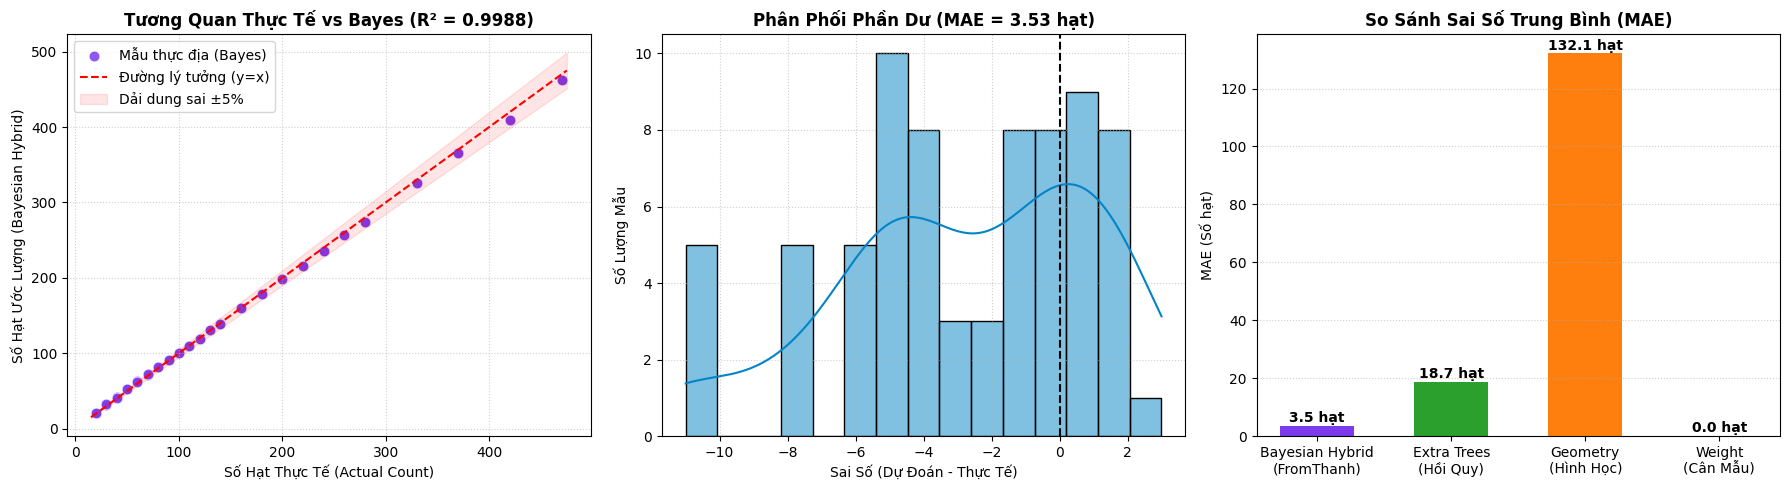

In [6]:
# =============================================================================
# 6. TRỰC QUAN HÓA KẾT QUẢ SO SÁNH (VISUAL ANALYTICS)
# =============================================================================
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from pathlib import Path

RESULTS_DIR = TEST_DATA_DIR / 'benchmark_results'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

if len(valid_eval) > 0:
    plt.figure(figsize=(18, 5))

    # Đồ thị 1: Actual vs Predicted Scatter kèm dải dung sai
    plt.subplot(1, 3, 1)
    sns.scatterplot(data=valid_eval, x='Actual_Count', y='Final_Estimate', color='#7c3aed', s=60, alpha=0.85, label='Mẫu thực địa (Bayes)')
    min_val = min(valid_eval['Actual_Count'].min(), valid_eval['Final_Estimate'].min()) - 5
    max_val = max(valid_eval['Actual_Count'].max(), valid_eval['Final_Estimate'].max()) + 5
    plt.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=1.5, label='Đường lý tưởng (y=x)')
    plt.fill_between([min_val, max_val], [min_val * 0.95, max_val * 0.95], [min_val * 1.05, max_val * 1.05],
                     color='red', alpha=0.1, label='Dải dung sai ±5%')
    plt.title(f'Tương Quan Thực Tế vs Bayes (R² = {r2:.4f})', fontsize=12, fontweight='bold')
    plt.xlabel('Số Hạt Thực Tế (Actual Count)')
    plt.ylabel('Số Hạt Ước Lượng (Bayesian Hybrid)')
    plt.legend(loc='upper left')
    plt.grid(True, linestyle=':', alpha=0.6)

    # Đồ thị 2: Phân phối sai số phần dư (Residuals)
    plt.subplot(1, 3, 2)
    residuals = valid_eval['Final_Estimate'] - valid_eval['Actual_Count']
    sns.histplot(residuals, kde=True, color='#0284c7', bins=15)
    plt.axvline(0, color='black', linestyle='--', linewidth=1.5)
    plt.title(f'Phân Phối Phần Dư (MAE = {mae:.2f} hạt)', fontsize=12, fontweight='bold')
    plt.xlabel('Sai Số (Dự Đoán - Thực Tế)')
    plt.ylabel('Số Lượng Mẫu')
    plt.grid(True, linestyle=':', alpha=0.6)

    # Đồ thị 3: So sánh đối đầu MAE giữa 4 phương pháp
    plt.subplot(1, 3, 3)
    methods = ['Bayesian Hybrid\n(FromThanh)', 'Extra Trees\n(Hồi Quy)', 'Geometry\n(Hình Học)', 'Weight\n(Cân Mẫu)']
    errors = [err_bayes, err_reg, err_geo, err_wt]
    colors = ['#7c3aed', '#2ca02c', '#ff7f0e', '#0284c7']
    bars = plt.bar(methods, errors, color=colors, width=0.55)
    for bar in bars:
        yval = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.3, f'{yval:.1f} hạt', ha='center', va='bottom', fontweight='bold')
    plt.title('So Sánh Sai Số Trung Bình (MAE)', fontsize=12, fontweight='bold')
    plt.ylabel('MAE (Số hạt)')
    plt.grid(axis='y', linestyle=':', alpha=0.6)

    plt.tight_layout()

    # Tự động lưu ảnh biểu đồ phân tích độ phân giải cao
    plot_img_path = RESULTS_DIR / 'benchmark_visual_analytics.png'
    plt.savefig(plot_img_path, dpi=300, bbox_inches='tight')
    print(f"📊 Đã tự động lưu đồ thị phân tích trực quan: {plot_img_path}")

    plt.show()


In [7]:
# =============================================================================
# 7. XUẤT TOÀN BỘ KẾT QUẢ ĐÁNH GIÁ & BÁO CÁO NGHIỆM THU
# =============================================================================
import os
import sys
import json
import shutil
import datetime
import numpy as np
import pandas as pd
from pathlib import Path

# 7.1 Thư mục lưu trữ chuyên biệt
RESULTS_DIR = TEST_DATA_DIR / 'benchmark_results'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")

# 7.2 Tính toán bổ sung phần dư nếu chưa có
if 'Error' not in benchmark_df.columns and 'Final_Estimate' in benchmark_df.columns:
    benchmark_df['Error'] = benchmark_df['Final_Estimate'] - benchmark_df['Actual_Count']

# 7.3 Xuất bảng kết quả chi tiết ra Excel & CSV (Bản cố định + Bản timestamp)
out_excel_latest = RESULTS_DIR / 'benchmark_100_results.xlsx'
out_csv_latest = RESULTS_DIR / 'benchmark_100_results.csv'
out_excel_ts = RESULTS_DIR / f'benchmark_100_results_{timestamp}.xlsx'
out_excel_root = TEST_DATA_DIR / 'benchmark_100_results.xlsx'

benchmark_df.to_excel(out_excel_latest, index=False)
benchmark_df.to_excel(out_excel_ts, index=False)
benchmark_df.to_excel(out_excel_root, index=False)
benchmark_df.to_csv(out_csv_latest, index=False, encoding='utf-8-sig')

# 7.4 Xuất tóm tắt chỉ số Metrics ra JSON
metrics_summary = {
    "evaluation_timestamp": datetime.datetime.now().isoformat(),
    "total_samples": int(len(benchmark_df)),
    "valid_samples": int(len(valid_eval)),
    "core_metrics": {
        "r2_score": round(float(r2), 4) if 'r2' in locals() else None,
        "mae_seeds": round(float(mae), 4) if 'mae' in locals() else None,
        "rmse_seeds": round(float(rmse), 4) if 'rmse' in locals() else None,
        "mape_percent": round(float(mape), 4) if 'mape' in locals() else None,
        "ci90_coverage_pct": round(float(ci90_coverage), 2) if 'ci90_coverage' in locals() else None,
        "within_3_seeds_pct": round(float(within_3_seeds), 2) if 'within_3_seeds' in locals() else None,
        "within_5_seeds_pct": round(float(within_5_seeds), 2) if 'within_5_seeds' in locals() else None,
        "within_5_pct_tolerance": round(float(within_5_pct), 2) if 'within_5_pct' in locals() else None,
        "within_10_pct_tolerance": round(float(within_10_pct), 2) if 'within_10_pct' in locals() else None,
        "avg_latency_ms": round(float(avg_latency), 2) if 'avg_latency' in locals() else None
    },
    "method_mae_comparison": {
        "bayesian_hybrid_fromthanh": round(float(err_bayes), 4),
        "extra_trees_regression": round(float(err_reg), 4),
        "geometry_heuristic": round(float(err_geo), 4),
        "electronic_scale_weight": round(float(err_wt), 4)
    }
}

metrics_json_path = RESULTS_DIR / 'benchmark_metrics_summary.json'
with open(metrics_json_path, 'w', encoding='utf-8') as f:
    json.dump(metrics_summary, f, ensure_ascii=False, indent=4)

# 7.5 Xuất Báo Cáo Nghiệm Thu Tổng Thể ra Text Report
top_best = valid_eval.sort_values(by='Abs_Error').head(5)
top_worst = valid_eval.sort_values(by='Abs_Error', ascending=False).head(5)
cols_show = ['Sample_ID', 'Actual_Count', 'Final_Estimate', 'CI90_Lower', 'CI90_Upper', 'Abs_Error', 'Pct_Error']
cols_exist = [c for c in cols_show if c in valid_eval.columns]

report_content = f"""================================================================================
🌾 BÁO CÁO KẾT QUẢ KIỂM NGHIỆM HỆ THỐNG RICE VISION AI (BAYESIAN SOTA)
================================================================================
Thời gian kiểm định       : {datetime.datetime.now().strftime("%d/%m/%Y %H:%M:%S")}
Tổng số mẫu thử nghiệm    : {len(benchmark_df)} mẫu
Số mẫu dự đoán hợp lệ    : {len(valid_eval)} mẫu
Tốc độ xử lý trung bình   : {avg_latency:.1f} ms / mẫu ({1000/avg_latency:.1f} FPS)

--------------------------------------------------------------------------------
1. HIỆU NĂNG TỔNG QUAN (CORE ACCURACY METRICS — BAYESIAN HYBRID)
--------------------------------------------------------------------------------
- Hệ số tương quan (R² Score)       : {r2:.4f}
- Sai số tuyệt đối TB (MAE)         : {mae:.2f} hạt
- Sai số căn quân phương (RMSE)     : {rmse:.2f} hạt
- Tỷ lệ sai số phần trăm (MAPE)     : {mape:.2f}%
- Độ phủ Khoảng tin cậy 90% (CI90)  : {ci90_coverage:.1f}%
- Tỷ lệ mẫu đạt sai số <= 3 hạt     : {within_3_seeds:.1f}%
- Tỷ lệ mẫu đạt sai số <= 5 hạt     : {within_5_seeds:.1f}%
- Tỷ lệ mẫu đạt dung sai <= 5%      : {within_5_pct:.1f}%
- Tỷ lệ mẫu đạt dung sai <= 10%     : {within_10_pct:.1f}%

--------------------------------------------------------------------------------
2. SO SÁNH ĐỐI ĐẦU VỚI CÁC PHƯƠNG PHÁP BASELINE
--------------------------------------------------------------------------------
- Bayesian Hybrid (FromThanh SOTA)  : MAE = {err_bayes:.2f} hạt
- Extra Trees (Mô hình Hồi quy cũ)  : MAE = {err_reg:.2f} hạt
- Thuần Hình Học (Geometry Packing) : MAE = {err_geo:.2f} hạt
- Cân Điện Tử (Weight-based)        : MAE = {err_wt:.2f} hạt

--------------------------------------------------------------------------------
3. TOP 5 MẪU ĐẠT ĐỘ CHÍNH XÁC CAO NHẤT
--------------------------------------------------------------------------------
{top_best[cols_exist].to_string(index=False)}

--------------------------------------------------------------------------------
4. TOP 5 MẪU CẦN LƯU Ý (SAI SỐ LỚN NHẤT ĐỂ PHÂN TÍCH)
--------------------------------------------------------------------------------
{top_worst[cols_exist].to_string(index=False)}

================================================================================
📂 TẬP TIN KẾT QUẢ ĐÃ LƯU TRỮ TẠI: {RESULTS_DIR}
- Bảng chi tiết Excel : {out_excel_latest.name}
- Bảng chi tiết CSV   : {out_csv_latest.name}
- Tóm tắt chỉ số JSON : {metrics_json_path.name}
- Báo cáo nghiệm thu  : benchmark_report.txt
- Đồ thị trực quan    : benchmark_visual_analytics.png
================================================================================
"""

report_txt_path = RESULTS_DIR / 'benchmark_report.txt'
with open(report_txt_path, 'w', encoding='utf-8') as f:
    f.write(report_content)

# 7.6 Tự động đóng gói file ZIP toàn bộ thư mục kết quả để tiện tải về
zip_path = TEST_DATA_DIR / 'benchmark_results_bundle'
shutil.make_archive(str(zip_path), 'zip', str(RESULTS_DIR))

print("=" * 80)
print(f"✅ ĐÃ HOÀN TẤT LƯU TRỮ TOÀN BỘ KẾT QUẢ ĐÁNH GIÁ:")
print("=" * 80)
print(f"   💾 1. Excel Kết Quả         : {out_excel_latest}")
print(f"   💾 2. CSV Kết Quả           : {out_csv_latest}")
print(f"   💾 3. Metrics Summary JSON  : {metrics_json_path}")
print(f"   💾 4. Báo Cáo Nghiệm Thu TXT: {report_txt_path}")
print(f"   📦 5. Gói ZIP Tổng Hợp      : {zip_path}.zip")
print(f"   📁 Thư mục kết quả hoàn chỉnh: {RESULTS_DIR}")
print("=" * 80)

# 7.7 Hiển thị Top 10 mẫu tốt nhất
print("\n🌟 TOP 10 MẪU CÓ ĐỘ CHÍNH XÁC CAO NHẤT:")
display_cols = ['Sample_ID', 'Actual_Count', 'Final_Estimate', 'CI90_Lower', 'CI90_Upper', 'Abs_Error', 'Pct_Error', 'Latency_ms']
display_exist = [c for c in display_cols if c in valid_eval.columns]
valid_eval.sort_values(by='Abs_Error').head(10)[display_exist]


✅ ĐÃ HOÀN TẤT LƯU TRỮ TOÀN BỘ KẾT QUẢ ĐÁNH GIÁ:
   💾 1. Excel Kết Quả         : /content/drive/MyDrive/NGHIÊN CỨU KHOA HỌC/GROUP_MEMBERS/NGUYEN MINH TRI/MAIN_SOURCES/AI_SERVICES/test_data/benchmark_results/benchmark_100_results.xlsx
   💾 2. CSV Kết Quả           : /content/drive/MyDrive/NGHIÊN CỨU KHOA HỌC/GROUP_MEMBERS/NGUYEN MINH TRI/MAIN_SOURCES/AI_SERVICES/test_data/benchmark_results/benchmark_100_results.csv
   💾 3. Metrics Summary JSON  : /content/drive/MyDrive/NGHIÊN CỨU KHOA HỌC/GROUP_MEMBERS/NGUYEN MINH TRI/MAIN_SOURCES/AI_SERVICES/test_data/benchmark_results/benchmark_metrics_summary.json
   💾 4. Báo Cáo Nghiệm Thu TXT: /content/drive/MyDrive/NGHIÊN CỨU KHOA HỌC/GROUP_MEMBERS/NGUYEN MINH TRI/MAIN_SOURCES/AI_SERVICES/test_data/benchmark_results/benchmark_report.txt
   📦 5. Gói ZIP Tổng Hợp      : /content/drive/MyDrive/NGHIÊN CỨU KHOA HỌC/GROUP_MEMBERS/NGUYEN MINH TRI/MAIN_SOURCES/AI_SERVICES/test_data/benchmark_results_bundle.zip
   📁 Thư mục kết quả hoàn chỉnh: /content/driv

,Sample_ID,Actual_Count,Final_Estimate,CI90_Lower,CI90_Upper,Abs_Error,Pct_Error,Latency_ms
25,M0026,140.0,140.0,119.0,165.0,0.0,0.0,26335.382743
31,M0032,160.0,160.0,135.0,188.0,0.0,0.0,31364.789518
30,M0031,160.0,160.0,135.0,188.0,0.0,0.0,36850.936869
29,M0030,160.0,160.0,135.0,188.0,0.0,0.0,33691.097982
19,M0020,110.0,110.0,88.0,6102.0,0.0,0.0,2361.928493
18,M0019,110.0,110.0,88.0,6102.0,0.0,0.0,2549.839814
17,M0018,100.0,100.0,80.0,5627.0,0.0,0.0,4126.914559
16,M0017,100.0,100.0,85.0,117.0,0.0,0.0,3545.881579
0,M0001,20.0,21.0,17.0,925.0,1.0,5.0,26109.677245
1,M0002,20.0,21.0,17.0,24.0,1.0,5.0,2466.195644
